# Practical Class Work - 3
## Title: Loan Approval Risk Model
### Business Goal
A bank wants to reduce losses. For each applicant, we must predict:
●
Bad risk (1) vs Good risk (0)
and produce a simple business decision recommendation.

## Notebook Structure and Task Flow
Notebook Setup, required libraries:

- pandas, numpy
- matplotlib
- scikit-learn

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1) Data Loading and Business Understanding
#### Task 1.1 Load dataset

- Load German Credit dataset into pandas DataFrame.

In [32]:
df = pd.read_csv('data/german.data', sep=r'\s+', header=None)# sep =r'\s+\ разделяй по одному или несколько пробелов
#header = None нет названия столбцов

Show:

- number of rows/columns
- first 5 rows
- target distribution (how many good vs bad)

In [33]:
df.shape

(1000, 21)

In [34]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [35]:
df[20].value_counts()

#in this dataset 1 - Good, 2 - Bad

20
1    700
2    300
Name: count, dtype: int64

#### Task 1.2 — Business interpretation

- What is a “default / bad risk” in a bank context?
- Why mistakes matter (false negatives vs false positives)

1. Default or bad risk means that a person may not be able to repay the loan. So the goal of this task is to predict whether the bank should approve a loan for a customer or not.

2. Mistakes are important because they can lead to financial losses. A false negative means that the model predicts a bad-risk customer as good, so the bank may approve a loan to a person who may not repay it. A false positive means that the model predicts a good customer as bad, so the bank may reject a reliable customer and lose potential profit. Therefore, both mistakes are important, but false negatives are usually more costly for the bank.

## 2) Data Quality and Simple EDA
#### Task 2.1 Missing values & data types

- Check missing values
- Identify numeric vs categorical features

In [36]:
df = df.rename(columns={
    1: 'duration',
    4: 'credit_amount',
    7: 'installment_rate',
    10: 'residence_since',
    12: 'age',
    15: 'existing_credits',
    17: 'people_liable',
    20: 'target'
})

In [37]:
df.isnull().sum()

0                   0
duration            0
2                   0
3                   0
credit_amount       0
5                   0
6                   0
installment_rate    0
8                   0
9                   0
residence_since     0
11                  0
age                 0
13                  0
14                  0
existing_credits    0
16                  0
people_liable       0
18                  0
19                  0
target              0
dtype: int64

In [38]:
cat_col = df.select_dtypes(include=['object']).columns
num_col = df.select_dtypes(exclude=['object']).columns

print(cat_col)
print(num_col)

Index([0, 2, 3, 5, 6, 8, 9, 11, 13, 14, 16, 18, 19], dtype='object')
Index(['duration', 'credit_amount', 'installment_rate', 'residence_since',
       'age', 'existing_credits', 'people_liable', 'target'],
      dtype='object')


#### Task 2.2 Correlation

- Compute correlation matrix for numeric columns
- Pick Top-3 numeric features most correlated with the target

In [39]:
df[num_col].corr(method='pearson')

,duration,credit_amount,installment_rate,residence_since,age,existing_credits,people_liable,target
duration,1.000000,0.624984,0.074749,0.034067,-0.036136,-0.011284,-0.023834,0.214927
credit_amount,0.624984,1.000000,-0.271316,0.028926,0.032716,0.020795,0.017142,0.154739
installment_rate,0.074749,-0.271316,1.000000,0.049302,0.058266,0.021669,-0.071207,0.072404
residence_since,0.034067,0.028926,0.049302,1.000000,0.266419,0.089625,0.042643,0.002967
age,-0.036136,0.032716,0.058266,0.266419,1.000000,0.149254,0.118201,-0.091127
existing_credits,-0.011284,0.020795,0.021669,0.089625,0.149254,1.000000,0.109667,-0.045732
people_liable,-0.023834,0.017142,-0.071207,0.042643,0.118201,0.109667,1.000000,-0.003015
target,0.214927,0.154739,0.072404,0.002967,-0.091127,-0.045732,-0.003015,1.000000


Duration, credit amount, and age have the strongest absolute correlations with the target among numerical features. This suggests that the loan duration, amount of credit, and the proportion of income used for repayments may help distinguish good-risk and bad-risk customers. However, correlation alone does not mean that these features are sufficient for accurate prediction.

In [40]:
df['target'] = df['target'].map({1:0, 2: 1}) # made this 'cause firstly 1 meant for good risk, 2 for bad risk

df.columns = df.columns.astype(str)

## 3) Preprocessing
#### Task 3.1 Split train/test

- Split into train/test (e.g., 80/20)
- Use random_state for reproducibility

In [41]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

new_num_col = X.select_dtypes(exclude='object').columns
new_cat_col = X.select_dtypes(include='object').columns

df[new_num_col].head()

,duration,credit_amount,installment_rate,residence_since,age,existing_credits,people_liable
0,6,1169,4,4,67,2,1
1,48,5951,2,2,22,1,1
2,12,2096,2,3,49,1,2
3,42,7882,2,4,45,1,2
4,24,4870,3,4,53,2,2


#### Task 3.2 Prepare pipeline

- Categorical → OneHotEncode
- Numeric → StandardScaler (if required)

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

log_reg = LogisticRegression()
dec_tree = DecisionTreeClassifier(random_state=42)
knn_class = KNeighborsClassifier()


full_transform = ColumnTransformer([
    ('cat', OneHotEncoder(), new_cat_col),
    ('num', StandardScaler(), new_num_col)
])

log_pipeline = Pipeline([
    ('full', full_transform),
    ('log_reg', log_reg)
])

dec_tree_pipeline = Pipeline([
    ('full', full_transform),
    ('dec_tree', dec_tree)
])

knn_pipeline = Pipeline([
    ('full', full_transform),
    ('knn', knn_class)
])

## 4) Build 3 Baseline Models (No Tuning)
Train exactly these 3 models:
1. Logistic Regression
2. Decision Tree
3. kNN

#### Task 4.1 Train models

- Fit each model using the same preprocessing pipeline.

In [43]:
log_pipeline.fit(X_train,y_train)
dec_tree_pipeline.fit(X_train,y_train)
knn_pipeline.fit(X_train, y_train)

,steps,"[('full', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Task 4.2 Evaluate models

For each model, compute:

- Accuracy
- Confusion Matrix
- Precision, Recall, F1

In [44]:
from sklearn.metrics import accuracy_score

log_pred = log_pipeline.predict(X_test)
log_acc = accuracy_score(y_test, log_pred)

tree_pred = dec_tree_pipeline.predict(X_test)
tree_acc = accuracy_score(y_test, tree_pred)

knn_pred = knn_pipeline.predict(X_test)
knn_acc = accuracy_score(y_test,knn_pred)

print(f'Accuracy for Logistic Regression is {log_acc}')
print(f'Accuracy for Decision Tree is {tree_acc}')
print(f'Accuracy for Knn is {knn_acc}')

Accuracy for Logistic Regression is 0.78
Accuracy for Decision Tree is 0.625
Accuracy for Knn is 0.725


In [45]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, log_pred))
print()
print(confusion_matrix(y_test, tree_pred))
print()
print(confusion_matrix(y_test, knn_pred))

[[124  16]
 [ 28  32]]

[[100  40]
 [ 35  25]]

[[124  16]
 [ 39  21]]


In [46]:
from sklearn.metrics import precision_score, recall_score

print('Results for Logistic Regression')
print(precision_score(y_test, log_pred))
print(recall_score(y_test, log_pred))

print()

print('Results for Decision Tree')
print(precision_score(y_test, tree_pred))
print(recall_score(y_test, tree_pred))

print()

print('Results for Knn')
print(precision_score(y_test, knn_pred))
print(recall_score(y_test, knn_pred))

Results for Logistic Regression
0.6666666666666666
0.5333333333333333

Results for Decision Tree
0.38461538461538464
0.4166666666666667

Results for Knn
0.5675675675675675
0.35


In [47]:
from sklearn.metrics import f1_score

print(f'F1_score for Logistic Regression is {f1_score(y_test,log_pred)}')
print(f'F1_score for Decision tree is {f1_score(y_test,tree_pred)}')
print(f'F1_score for Knn is {f1_score(y_test,knn_pred)}')

F1_score for Logistic Regression is 0.5925925925925926
F1_score for Decision tree is 0.4
F1_score for Knn is 0.4329896907216495


#### In credit risk, which is worse: approving a bad client (FN) or rejecting a good one (FP)? Explain.

In my opinion approving bad client worse than rejecting a good one, because of course you loose money in this two sitatuions, but when you approving a bad client you 100% loose more money.

## 5) Simple “Business Threshold”
Logistic regression outputs probabilities
Compare 3 thresholds
Compute confusion matrix and metrics (f1, recall, precision) for for test set:

- Threshold = 0.65
- Threshold = 0.50
- Threshold = 0.35

In [48]:
threshold = 0.65

bad_prob = log_pipeline.predict_proba(X_test)[:,1]#дается массив чисел good = 0 index, bad = 1, берем все плохие индексы, [:,1] взять все строки индексом 1
pred_threshold = (bad_prob >= threshold).astype(int) # превращает True - 1, False - 0

def print_f1_rec_prec_conf(pred_threshold):
    print(f'Precision is {precision_score(y_test, pred_threshold)}')
    print(f'Recall is {recall_score(y_test, pred_threshold)}')
    print(f'F1 score is {f1_score(y_test, pred_threshold)}')

print_f1_rec_prec_conf(pred_threshold)

print('Confusion Matrix')
print(confusion_matrix(y_test, pred_threshold))



Precision is 0.7586206896551724
Recall is 0.36666666666666664
F1 score is 0.4943820224719101
Confusion Matrix
[[133   7]
 [ 38  22]]


In [49]:
threshold = 0.5

bad_prob = log_pipeline.predict_proba(X_test)[:,1]#дается массив чисел good = 0 index, bad = 1, берем все плохие индексы, [:,1] взять все строки индексом 1
pred_threshold = (bad_prob >= threshold).astype(int) # превращает True - 1, False - 0



print_f1_rec_prec_conf(pred_threshold)

print('Confusion Matrix')
print(confusion_matrix(y_test, pred_threshold))



Precision is 0.6666666666666666
Recall is 0.5333333333333333
F1 score is 0.5925925925925926
Confusion Matrix
[[124  16]
 [ 28  32]]


In [50]:
threshold = 0.35

bad_prob = log_pipeline.predict_proba(X_test)[:,1]#дается массив чисел good = 0 index, bad = 1, берем все плохие индексы, [:,1] взять все строки индексом 1
pred_threshold = (bad_prob >= threshold).astype(int) # превращает True - 1, False - 0




print_f1_rec_prec_conf(pred_threshold)

print('Confusion Matrix')
print(confusion_matrix(y_test, pred_threshold))


Precision is 0.5974025974025974
Recall is 0.7666666666666667
F1 score is 0.6715328467153284
Confusion Matrix
[[109  31]
 [ 14  46]]


#### Explain:

1) Which threshold you recommend and why
2) How does lowering the threshold change the number of rejected clients?
3) Which threshold reduces the number of bad clients approved?
4) Which threshold increases the number of good clients rejected?
5) If you were the Head of Risk, which threshold would you recommend and why?

Precision - how much you can believe a model(наскок можешь доверять модели то что она верно ответит)

Recall - from all bad score clients how many of them model takes(из всех плохих клиентов скок модель ловит)

1) As we can see from result, setting a different threshold can change recall/precision and of course f1 score of model. So from the first model we observe that model really good identifies bad score clients who was identified as bad client score, but more often don't see bad clients score, so when model see bad client likely it will say that it's a bad client rather then good, and there is working precision/recall tradeoff, that happens when we change tradeoff. In this case recall is really bad only 36% percent model catches bad clients and for bank is crucial that model needs to have big recall, because with big recall model is more carefull and this is more better than when precision is big. So in my opinion threshold = 0.35 is winnig if we want to catch more bad clients.

2) When we lower threshold recall is getting higher and precision is getting lower, and as i said before precision/recall tradeoff. If we compare threshold 0.65 and 0.35 we can see that clients who has good score marking as bad score getting more and and quantity of bad client who was rejected also getting bigger.

3) Threshold = 0.35

4) Threshold = 0.35

5) I would take threshold = 0.35 , because for bank approving bad client worse than rejecting a good one, because of course you loose money in this two sitatuions, but when you approving a bad client you 100% loose more money.

## 6) Production-Oriented task: “Manual Review Queue”
In real banks, not all decisions are automatic.
#### Task 6.1 Create 3 decision zones using probability
Using logistic regression probability p:

- Auto-approve: p < 0.20
- Manual review: 0.20 ≤ p ≤ 0.50
- Auto-reject: p > 0.50

Deliverables:

- Count how many applications fall in each zone
- Business interpretation: how this reduces workload and risk

In [51]:
bad_log_prob = log_pipeline.predict_proba(X_test)[:,1]
auto_prob = (bad_log_prob < 0.2).astype(int)

auto_approve = auto_prob.sum()
auto_approve



np.int64(91)

In [52]:
bad_log_prob = log_pipeline.predict_proba(X_test)[:,1]
manual_prob = ((bad_log_prob >= 0.2).astype(int)) & ((bad_log_prob <= 0.5).astype(int))

manual_review = manual_prob.sum()
manual_review


np.int64(61)

In [53]:
bad_log_prob = log_pipeline.predict_proba(X_test)[:,1]
auto_prob = (bad_log_prob > 0.5).astype(int)

auto_reject = auto_prob.sum()
auto_reject

np.int64(48)

1) For auto-approve, the model estimates a low probability of bad credit risk. These applications can be approved automatically, which saves employees’ time and reduces workload.

2) For manual review, the model is not confident enough to make an automatic decision. A bank employee can review additional information and decide whether the client is a Good or Bad risk.

3) For auto-reject, the model estimates a high probability of bad credit risk. These applications can be rejected automatically, which reduces the risk of approving Bad clients and also saves employees’ time.

## 7) Business Demonstration
Create a final markdown section:
Business Demo: Loan Approval Risk Model
Include:
1. Executive summary

- what dataset about

- what goal

- best model chosen

- key metric result

- recommended threshold

- how manual review queue works

2. One table comparing models
Rows: models
Columns: Accuracy, Recall (bad class), F1, comment (1 short sentence)
3. One visual

- Confusion matrix plot (matplotlib)
4. Example: 3 applicants
Take 3 rows from test set and show:

- probability
- predicted decision zone (approve/review/reject)
- 1–2 sentence explanation for each (business style)

1) This dataset is about people who tries to receive credit in the bank
2) Goal of this work was to predict either client has a bad score or good score, depending on this we decide give credit for client or no
3) Logistic Regression is the best model so far
4) Baseline accuracy for Logistic Regression is 0.78, precision - 0.66 and recall - 0.53
5) Recommended threshold in my view is 0.35 because recall is high - 0.77 with this threshold and f1 score - 0.67
6) Manual review work like this, if probability in range 0.2 to 0.5, we can't give work for model, so employee needs to check more info about client, to answer the question "Is it a bad risk or good?"

In [54]:
table_col = ['Models', 'Accuracy', 'Recall', 'F1']

models_col = ['Log Reg', 'Decision Tree', 'KNN']
acc_col = [log_acc, tree_acc, knn_acc]
recall_col = [recall_score(y_test, log_pred), recall_score(y_test, tree_pred), recall_score(y_test, knn_pred)]
f1_col = [f1_score(y_test,log_pred), f1_score(y_test,tree_pred), f1_score(y_test,knn_pred)]
comments = ['Logistic Regression: best overall baseline model', 'Decision Tree: lowest overall performance on the test set.', 'kNN: better than the tree, but weaker than Logistic Regression.']


table = pd.DataFrame({
    'Models':models_col,
    'Accuracy':acc_col,
    'Recall':recall_col,
    'F1':f1_col,
    'Comment':comments
})
table

,Models,Accuracy,Recall,F1,Comment
0,Log Reg,0.780,0.533333,0.592593,Logistic Regression: best overall baseline model
1,Decision Tree,0.625,0.416667,0.400000,Decision Tree: lowest overall performance on t...
2,KNN,0.725,0.350000,0.432990,"kNN: better than the tree, but weaker than Log..."


As we can see, Logistic Regression wins in all parameteres

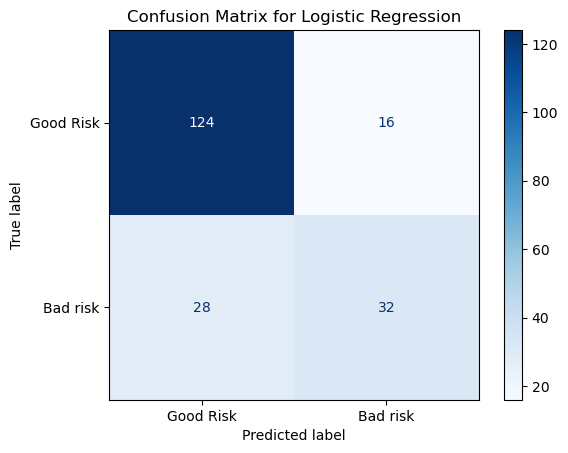

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

log_conf = confusion_matrix(y_test, log_pred)
disp_log_conf = ConfusionMatrixDisplay(confusion_matrix = log_conf, display_labels = ['Good Risk', 'Bad risk'])

disp_log_conf.plot(cmap = plt.cm.Blues)
plt.title("Confusion Matrix for Logistic Regression")
plt.show()



Logistic Regression: best overall baseline model.

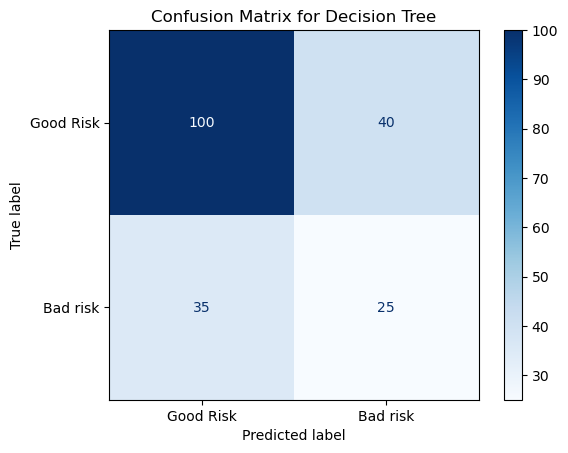

In [56]:
tree_conf = confusion_matrix(y_test, tree_pred)
disp_tree_conf = ConfusionMatrixDisplay(confusion_matrix = tree_conf, display_labels = ['Good Risk', 'Bad risk'])

disp_tree_conf.plot(cmap = plt.cm.Blues)
plt.title("Confusion Matrix for Decision Tree")
plt.show()

Decision Tree: lowest performance on the test set.

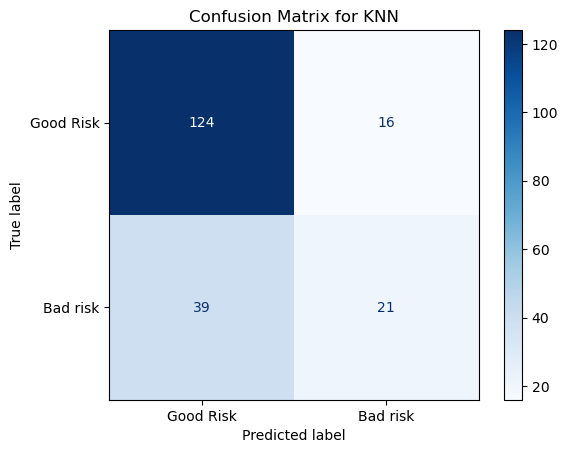

In [57]:
knn_conf = confusion_matrix(y_test, knn_pred)
disp_knn_conf = ConfusionMatrixDisplay(confusion_matrix = knn_conf, display_labels = ['Good Risk', 'Bad risk'])

disp_knn_conf.plot(cmap = plt.cm.Blues)
plt.title("Confusion Matrix for KNN")
plt.show()

kNN: better than the tree, but weaker than Logistic Regression.

In [58]:
bad_log_prob = log_pipeline.predict_proba(X_test)[:,1]
bad_log_prob

three_candidates = [bad_log_prob[12],bad_log_prob[2], bad_log_prob[6]]

id = 0
for items in three_candidates:

    id= id + 1

    if items < 0.2:
        print(f'Application {id} - probaility {items} - Auto approve')
    elif items <=0.5:
        print(f'Application {id} - probaility {items} - Manual review')
    elif items > 0.5:
        print(f'Application {id} - probaility {items} - Auto reject')


    

Application 1 - probaility 0.01775549982490147 - Auto approve
Application 2 - probaility 0.6187684634208384 - Auto reject
Application 3 - probaility 0.21671202901803088 - Manual review


**Application 1 — probability: 0.018 — Auto-approve**

The predicted probability of bad credit risk is very low. The application can be approved automatically without manual review.

**Application 2 — probability: 0.619 — Auto-reject**

The predicted probability of bad credit risk is high. The application should be rejected automatically to reduce potential credit losses.

**Application 3 — probability: 0.217 — Manual review**

The predicted probability of bad credit risk is in the uncertain range. A credit analyst should review additional information before making the final decision.